#hi my name is mstafa
#subscribe my channel and
#ask me your question


#Github.com/mstafafarahani
#Mstafa.farahani@gmail.com
#You tube: @GEEmap
#Channel telegram : @GEEmap
#Whatsapp +989381272118
#learning satelite imagery remote sensing

#I install and import packages

In [ ]:
%pip install pygis -q
import ee, geemap, pandas as pd, matplotlib.pyplot as plt

# I Register and Authenticate in Google Earth Engine
#you need to create account in earth engine
#to run code

#for example my account is"ee-mstafafarahanit54f"
#replace your account intead of mine

In [ ]:
try:
    ee.Initialize(project='ee-mstafafarahanit54f')
except:
    ee.Authenticate()
    ee.Initialize(project='ee-mstafafarahanit54f')

#//vedio & code in my channel YouTube.com/@Geemap     mstafa.farahani@gmail.com

/*YOu CAN USE city or provinceORstate or country boundary , in this code i use city boundary

city = ee.FeatureCollection("WM/geoLab/geoBoundaries/600/ADM2")

provinceORstate = ee.FeatureCollection("FAO/GAUL_SIMPLIFIED_500m/2015/level1").

country = ee.FeatureCollection("FAO/GAUL/2015/level0").filter(ee.Filter.eq('ADM0_NAME', 'Kenya'))


replace city or country or provine to eachother


## Let's Show the map

In [ ]:
import geemap
Map = geemap.Map(center=[0, 0], zoom=2, basemap='HYBRID')
country = ee.FeatureCollection("FAO/GAUL/2015/level0").filter(ee.Filter.eq('ADM0_NAME', 'Kenya'))
Map.centerObject(country, 6)
Map.addLayer(country, {}, "Country")

# Shortened cropland collection processing and mapping
cropland_ic = ee.ImageCollection("MODIS/061/MCD12Q1").select('LC_Type1').filterBounds(country).filterDate('2000-01-01', '2023-01-01')
print('Image count:', cropland_ic.size().getInfo())

# Map and add the cropland layers in a few concise lines
cropland_areas = cropland_ic.map(lambda img: img.clip(country).eq(13).selfMask().multiply(ee.Image.pixelArea().divide(1e6)).set({'system:time_start': img.get('system:time_start')}))
Map.addLayer(cropland_areas.sum(), {'min': 32, 'max': 511, 'palette': ['1aff00']}, 'cropland Area Growth')
Map.add_legend(title="cropland Area Growth", legend_dict={'cropland Growth': '1aff00'})
Map

Image count: 22


Map(center=[0.5336326464913033, 37.86026492779483], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
print("Number of images in collection:", cropland_ic.size().getInfo())

Number of images in collection: 22


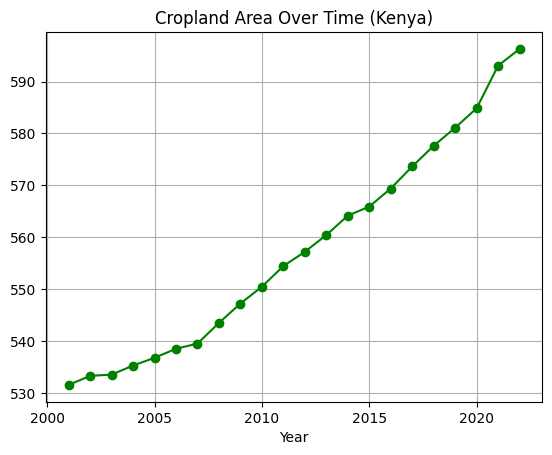

In [ ]:
import pandas as pd, matplotlib.pyplot as plt
# Fetch, clean, and plot in 4 lines
data = cropland_areas.map(lambda i: ee.Feature(None, {'y': ee.Date(i.get('system:time_start')).format('YYYY'), 'a': i.reduceRegion(ee.Reducer.sum(), country.geometry(), 500, maxPixels=1e13).get('LC_Type1')})).reduceColumns(ee.Reducer.toList(2), ['y', 'a']).get('list').getInfo()
pd.DataFrame(data, columns=['Year', 'Area']).dropna().astype({'Year': int}).plot(x='Year', y='Area', marker='o', color='green', legend=False, grid=True, title='Cropland Area Over Time (Kenya)')
plt.show()

#you're asking for truly direct download to your computer's Downloads folder from Colab —
#no Google Drive, no clicking, just straight to your machine.

In [ ]:
import pandas as pd
from google.colab import files

# Reuse the data variable computed in the previous cell
pd.DataFrame(data, columns=['year', 'cropland_area_km2']).dropna().to_csv('cropland_area_timeseries.csv', index=False)
files.download('cropland_area_timeseries.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

# Convert the pre-calculated 'data' list to a DataFrame
df_stats = pd.DataFrame(data, columns=['Year', 'Area_km2']).dropna()
df_stats['Year'] = df_stats['Year'].astype(int)
df_stats = df_stats.sort_values('Year')

# Calculate basic trend statistics
start_year, start_val = df_stats.iloc[0]['Year'], df_stats.iloc[0]['Area_km2']
end_year, end_val = df_stats.iloc[-1]['Year'], df_stats.iloc[-1]['Area_km2']

total_change = end_val - start_val
pct_change = (total_change / start_val) * 100
annual_rate = total_change / (end_year - start_year)

# Display a clean report summary
print(f"--- Cropland Dynamics Summary ({start_year} - {end_year}) ---")
print(f"Initial Cropland Area ({start_year}): {start_val:.2f} km²")
print(f"Final Cropland Area ({end_year}): {end_val:.2f} km²")
print(f"Total Growth: +{total_change:.2f} km² ({pct_change:+.2f}% change)")
print(f"Average Annual Expansion Rate: {annual_rate:+.2f} km²/year")

--- Cropland Dynamics Summary (2001.0 - 2022.0) ---
Initial Cropland Area (2001.0): 531.56 km²
Final Cropland Area (2022.0): 596.29 km²
Total Growth: +64.73 km² (+12.18% change)
Average Annual Expansion Rate: +3.08 km²/year


In [ ]:
# Yes, we can absolutely use this data for Machine Learning (ML)!
# Here are some of the main ways we can apply ML to this dataset:
#
# 1. Forecasting (Time Series): Predict future cropland area (e.g., estimating Kenya's cropland for 2025 or 2030).
# 2. Regression Analysis: Correlate this growth with external factors like annual rainfall, population growth, or temperature.
# 3. Anomaly Detection: Automatically detect years with abnormal drops (due to extreme droughts) or spikes.

import pandas as pd
import numpy as np

# Let's quickly prepare the dataset structure that an ML model would expect:
df_ml = pd.DataFrame(data, columns=['Year', 'Cropland_Area_km2']).dropna()
df_ml['Year'] = df_ml['Year'].astype(int)

# Creating features: lag features (previous year's area) help models learn temporal dependencies
df_ml['Prev_Year_Area'] = df_ml['Cropland_Area_km2'].shift(1)
df_ml['YoY_Change_km2'] = df_ml['Cropland_Area_km2'].diff()

print("--- Structured Feature Set Ready for ML Training ---")
print(df_ml.head())
print("\nThis structured dataset is ready for Scikit-Learn (Linear Regression, Random Forest) or ARIMA models!")

--- Structured Feature Set Ready for ML Training ---
   Year  Cropland_Area_km2  Prev_Year_Area  YoY_Change_km2
0  2001         531.562920             NaN             NaN
1  2002         533.305196      531.562920        1.742276
2  2003         533.554095      533.305196        0.248899
3  2004         535.296387      533.554095        1.742291
4  2005         536.789684      535.296387        1.493297

This structured dataset is ready for Scikit-Learn (Linear Regression, Random Forest) or ARIMA models!


In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Prepare features (X = Year) and target (y = Cropland Area)
clean_df = df_ml.dropna(subset=['Cropland_Area_km2'])
X = clean_df[['Year']].values
y = clean_df['Cropland_Area_km2'].values

# Train a simple Linear Regression model
model = LinearRegression().fit(X, y)

# Forecast for future years
future_years = np.array([[2025], [2030]])
predictions = model.predict(future_years)

print("--- Machine Learning Trend Forecasting (Linear Regression) ---")
for year, pred in zip(future_years.flatten(), predictions):
    print(f"Projected Cropland Area for {year}: {pred:.2f} km²")

--- Machine Learning Trend Forecasting (Linear Regression) ---
Projected Cropland Area for 2025: 599.66 km²
Projected Cropland Area for 2030: 615.23 km²


##code in my youtube chanel in description free use